In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
sns.set_palette('pastel')

In [2]:
df_rides = pd.read_csv('ride_hailing_dataset.csv')

In [3]:
print("Shape:", df_rides.shape)
print("Columns:", df_rides.columns.tolist())
print("\nHead:\n", df_rides.head())
print("\nInfo:")
df_rides.info()
print("\nDescribe:\n", df_rides.describe())
print("\nMissing values:\n", df_rides.isnull().sum())

Shape: (100, 8)
Columns: ['trip_id', 'city', 'service_type', 'fare', 'distance_km', 'payment_method', 'trip_rating', 'gender']

Head:
   trip_id       city service_type    fare  distance_km payment_method  \
0    T001     Lahore         Uber  984.44         17.2           Cash   
1    T002  Islamabad         Uber  539.46          2.5         Wallet   
2    T003    Karachi       Careem  401.60          8.0           Card   
3    T004     Lahore         Uber  932.56         16.2         Wallet   
4    T005     Lahore     Rickshaw  148.61         19.2           Card   

   trip_rating  gender  
0            3  Female  
1            5  Female  
2            4    Male  
3            3  Female  
4            5  Female  

Info:
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   trip_id         100 non-null    str    
 1   city            100 non-null    str  

In [4]:
cols = df_rides.columns.tolist()

In [5]:
# Q1: What is the average fare by service type?
fare_col = [c for c in cols if 'fare' in c.lower()][0]
service_col = [c for c in cols if 'service' in c.lower()][0]
fare_by_service = df_rides.groupby(service_col)[fare_col].agg(['count', 'mean', 'median', 'std', 'min', 'max'])
print(f"\nQ1 ({fare_col} by {service_col}):\n", fare_by_service)


Q1 (fare by service_type):
               count        mean   median         std     min     max
service_type                                                        
Careem           30  544.975000  474.660  274.970146  123.61  991.49
InDrive          23  573.514783  621.120  264.279316  107.35  952.15
Rickshaw         25  486.637200  496.470  272.366248  134.33  942.48
Uber             22  486.125455  508.905  239.126700  125.10  984.44


In [6]:
# Q2: Which city has the most trips?
city_col = [c for c in cols if 'city' in c.lower()][0]
city_counts = df_rides[city_col].value_counts()
print(f"\nQ2 (Trips by {city_col}):\n", city_counts)
print("City with most trips:", city_counts.index[0], "with", city_counts.iloc[0], "trips")


Q2 (Trips by city):
 city
Islamabad     29
Lahore        26
Karachi       23
Rawalpindi    22
Name: count, dtype: int64
City with most trips: Islamabad with 29 trips


In [7]:
# Q3: What is the average distance per trip?
dist_col = [c for c in cols if 'dist' in c.lower()][0]
avg_dist = df_rides[dist_col].mean()
print(f"\nQ3 ({dist_col}) - mean: {avg_dist:.4f}, median: {df_rides[dist_col].median():.4f}, std: {df_rides[dist_col].std():.4f}, min: {df_rides[dist_col].min()}, max: {df_rides[dist_col].max()}")


Q3 (distance_km) - mean: 9.6130, median: 9.7000, std: 5.2126, min: 1.2, max: 19.5


In [8]:
# Q4: Compare trip ratings by gender.
rating_col = [c for c in cols if 'rating' in c.lower()][0]
gender_col = [c for c in cols if 'gender' in c.lower()][0]
rating_by_gender = df_rides.groupby(gender_col)[rating_col].agg(['count', 'mean', 'median', 'std', 'min', 'max'])
print(f"\nQ4 ({rating_col} by {gender_col}):\n", rating_by_gender)


Q4 (trip_rating by gender):
         count      mean  median       std  min  max
gender                                             
Female     51  2.823529     3.0  1.465686    1    5
Male       49  3.326531     4.0  1.463269    1    5


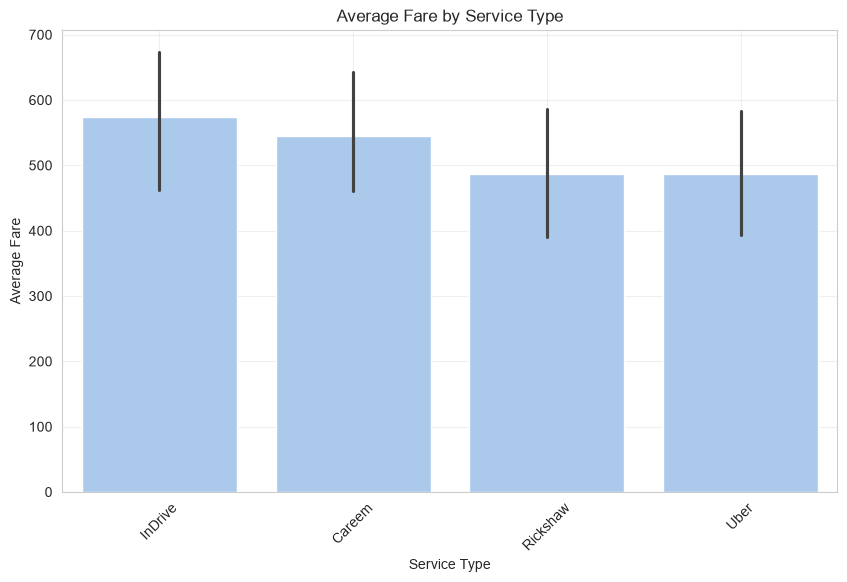

In [9]:
# Q5: Make a bar chart of service type vs. average fare.
avg_fare_by_service = df_rides.groupby(service_col)[fare_col].mean().sort_values(ascending=False)
plt.figure(figsize=(10, 6))
sns.barplot(data=df_rides, x=service_col, y=fare_col, estimator='mean', order=avg_fare_by_service.index)
plt.title('Average Fare by Service Type')
plt.xlabel('Service Type')
plt.ylabel('Average Fare')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.savefig('q5_fare_by_service.png', dpi=300, bbox_inches='tight')
plt.show()